# Chapter 2 — Theoretical Foundation of Diffusion Map

**Ho Chi Minh City University of Technology · 2026**

---

## Table of Contents

| § | Topic | Figure |
|---|-------|--------|
| 2.1 | [Mathematical Setting](#21-mathematical-setting) | Fig 2.1 |
| 2.2 | [Kernel-Based Affinity Graph](#22-kernel-based-affinity-graph) | Figs 2.2 – 2.3 |
| 2.3 | [Markov Operator and Random Walk Dynamics](#23-markov-operator-and-random-walk-dynamics) | Fig 2.4 |
| 2.4 | [Spectral Decomposition and Diffusion Coordinates](#24-spectral-decomposition-and-diffusion-coordinates) | Fig 2.5 |
| 2.5 | [Diffusion Distance and Its Interpretation](#25-diffusion-distance-and-its-interpretation) | Fig 2.6 |
| 2.6 | [Connection to Continuous Operators](#26-connection-to-continuous-operators) | — |
| 2.7 | [Role of Hyperparameters in Theory](#27-role-of-hyperparameters-in-theory) | Fig 2.7 |

---

In [13]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.linalg import eigh
from scipy.spatial.distance import cdist
from sklearn.datasets import make_swiss_roll, make_moons
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# ── Colorblind-safe palette (Wong 2011) ─────────────────────────────────────
CB = {
    'orange':    '#E69F00',
    'sky':       '#56B4E9',
    'green':     '#009E73',
    'yellow':    '#F0E442',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
    'black':     '#000000',
}

# ── Global rcParams (Q1-journal quality) ────────────────────────────────────
mpl.rcParams.update({
    'figure.dpi'                   : 150,
    'savefig.dpi'                  : 300,
    'font.size'                    : 11,
    'axes.titlesize'               : 12,
    'axes.labelsize'               : 11,
    'legend.fontsize'              : 10,
    'xtick.labelsize'              : 10,
    'ytick.labelsize'              : 10,
    'axes.spines.top'              : False,
    'axes.spines.right'            : False,
    'figure.constrained_layout.use': False,
})

# ── Diffusion Map core function ──────────────────────────────────────────────
def build_diffusion_map(X, epsilon='median', alpha=1.0, n_components=8):
    """
    Compute the Diffusion Map embedding of point cloud X.

    Parameters
    ----------
    X            : (n, d) array of observations
    epsilon      : kernel bandwidth; 'median' auto-selects median(||xi-xj||^2)
    alpha        : anisotropic normalisation exponent in [0, 1]
                   0 = no correction; 1 = full geometry-preserving correction
    n_components : number of eigenpairs to return (including trivial lambda_0=1)

    Returns
    -------
    lambdas : (n_components,) eigenvalues in descending order (lambda_0 ≈ 1)
    psi     : (n, n_components) right eigenvectors of P (diffusion basis)
    P       : (n, n) row-stochastic Markov transition matrix
    W       : (n, n) raw Gaussian kernel matrix
    W_tilde : (n, n) anisotropically normalised kernel
    eps     : actual epsilon value used
    """
    D2 = cdist(X, X, 'sqeuclidean')

    eps = float(np.median(D2[D2 > 0])) if epsilon == 'median' else float(epsilon)

    # Step 1 — Raw Gaussian kernel
    W = np.exp(-D2 / eps)

    # Step 2 — Anisotropic density normalisation
    q = W.sum(axis=1)
    W_tilde = W / np.outer(q**alpha, q**alpha)

    # Step 3 — Row-stochastic Markov matrix P = D^{-1} W̃
    d_tilde = W_tilde.sum(axis=1)
    P = W_tilde / d_tilde[:, None]

    # Step 4 — Symmetric conjugate  A = D^{-1/2} W̃ D^{-1/2}
    d_inv_sqrt = 1.0 / np.sqrt(d_tilde)
    A = W_tilde * np.outer(d_inv_sqrt, d_inv_sqrt)

    # Step 5 — Eigendecomposition of A (k largest eigenvalues)
    n = len(X)
    k = min(n_components, n - 1)
    vals, vecs = eigh(A, subset_by_index=[n - k, n - 1])
    vals = vals[::-1]          # descending order
    vecs = vecs[:, ::-1]

    # Step 6 — Convert to right eigenvectors of P: psi_l = D^{-1/2} v_l
    psi = vecs * d_inv_sqrt[:, None]
    for l in range(psi.shape[1]):
        norm = np.linalg.norm(psi[:, l])
        if norm > 0:
            psi[:, l] /= norm

    return vals, psi, P, W, W_tilde, eps



---
## §2.1 Mathematical Setting

Let $\mathcal{X} = \{x_1, x_2, \dots, x_n\} \subset \mathbb{R}^d$ denote observed data sampled from an unknown **low-dimensional manifold** $\mathcal{M}$ embedded in a high-dimensional ambient space.  The *manifold hypothesis* asserts that the intrinsic dimension $m \ll d$: the data lie near a curved surface rather than filling the full ambient space.

The objective of Diffusion Map is to construct coordinates that reflect **intrinsic connectivity on $\mathcal{M}$** rather than Euclidean geometry in $\mathbb{R}^d$.  The central difficulty is that **Euclidean distance is an unreliable surrogate for geodesic proximity on a curved manifold** — two points that are close in $\mathbb{R}^d$ may be far apart *along* the manifold, and vice versa.

**Figure 2.1** demonstrates this failure mode on the S-curve manifold ($n = 500$):

- **(a) Ambient space $\mathbb{R}^3$** — the data lie on a curved surface, yet Euclidean distance can conflate structurally unrelated regions.  **Pair A** (orange, $\bigstar$) is Euclidean-close but lies on *opposite* folds of the manifold; **Pair B** (green, $\bullet$) is Euclidean-far yet connected along the *same* arm.
- **(b) Intrinsic unrolled coordinates** — under manifold parameterisation, Pair A appears well separated (cross-fold) while Pair B appears nearby (same arm), indicating that ambient Euclidean distances can be misleading for curved manifolds.

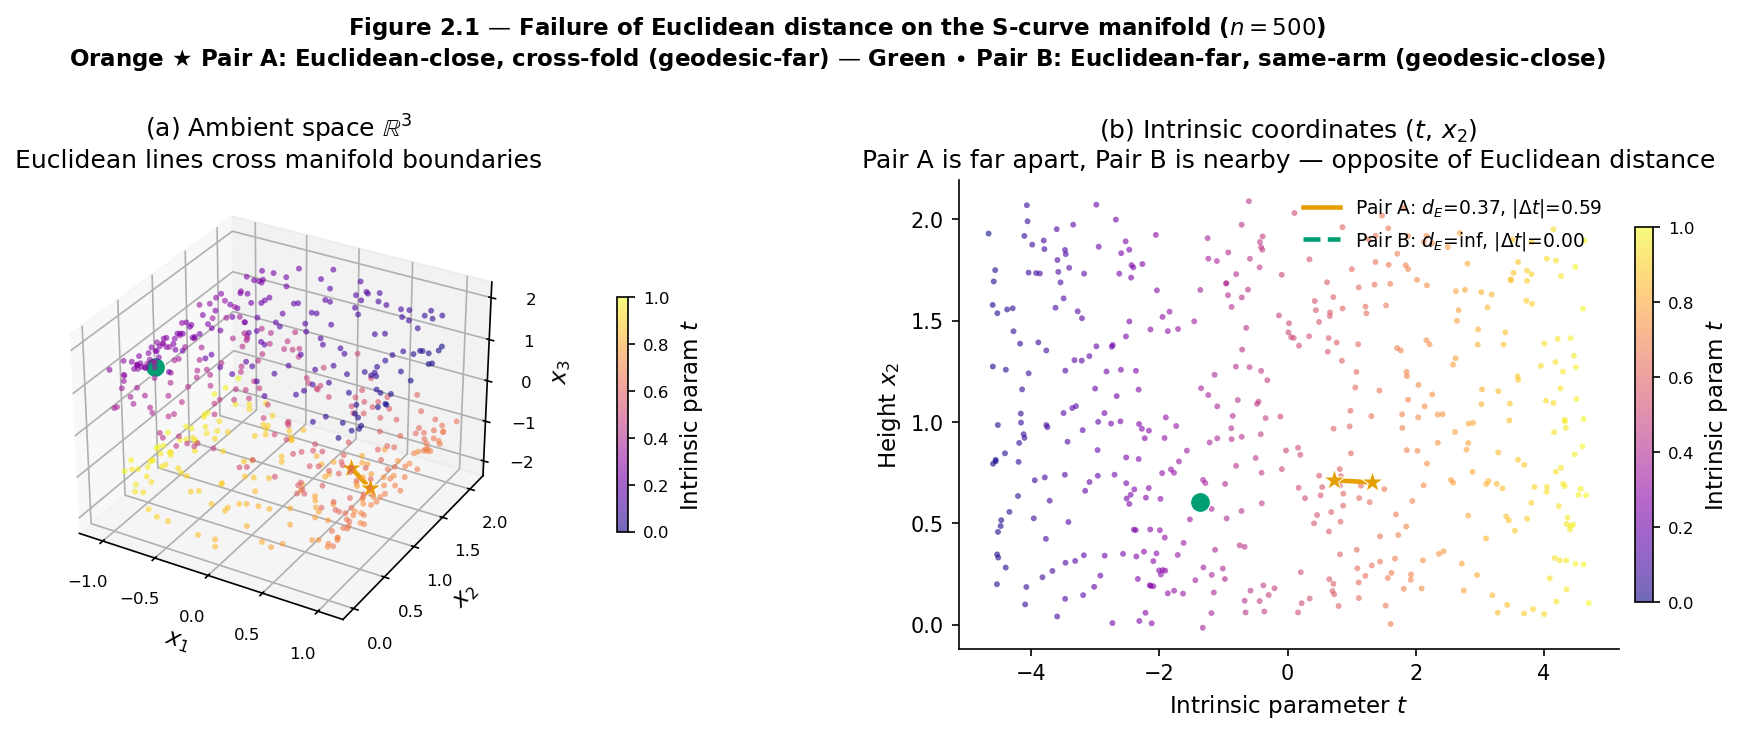

Saved: fig2_1_manifold_setting.pdf


In [14]:
# ── Figure 2.1 — Euclidean vs manifold distance on the S-curve ──────────────
from sklearn.datasets import make_s_curve

np.random.seed(0)
n_sc = 500
X_sc, t_sc = make_s_curve(n_samples=n_sc, noise=0.05, random_state=0)
# t_sc is the intrinsic parameter; X_sc[:,1] is the height
t_sc_n = (t_sc - t_sc.min()) / (t_sc.max() - t_sc.min())

# ── Find two characteristic point pairs ─────────────────────────────────────
from scipy.spatial.distance import cdist as _cdist

D2_sc = _cdist(X_sc, X_sc, 'sqeuclidean')
np.fill_diagonal(D2_sc, np.inf)

# Pair A: Euclidean-close BUT on opposite folds (|t difference| large)
# Search among the k Euclidean-nearest pairs
k_cand = 80
t_diff_mat = np.abs(t_sc[:, None] - t_sc[None, :])
candidate_pairs = np.argsort(D2_sc.ravel())[:k_cand * n_sc]
found_A = False
for flat in candidate_pairs:
    i, j = divmod(int(flat), n_sc)
    if i >= j:
        continue
    if t_diff_mat[i, j] > 0.55:       # opposite folds
        iA, jA = i, j
        found_A = True
        break
if not found_A:
    iA, jA = 0, 1   # fallback

# Pair B: Euclidean-far BUT on same fold (|t difference| small)
mask_same = (t_diff_mat < 0.08) & (D2_sc > np.percentile(D2_sc[np.isfinite(D2_sc)], 88))
same_far  = np.argwhere(mask_same)
if len(same_far):
    pick    = same_far[len(same_far) // 2]
    iB, jB  = int(pick[0]), int(pick[1])
else:
    iB, jB  = n_sc - 2, n_sc - 1

# ── Layout ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(13, 4.6))
fig.set_layout_engine('none')
fig.subplots_adjust(left=0.04, right=0.97, bottom=0.10, top=0.78, wspace=0.28)
fig.suptitle(
    r'Figure 2.1 — Failure of Euclidean distance on the S-curve manifold ($n = 500$)'
    '\n'
    r'Orange $\bigstar$ Pair A: Euclidean-close, cross-fold (geodesic-far) — '
    r'Green $\bullet$ Pair B: Euclidean-far, same-arm (geodesic-close)',
    fontsize=11, fontweight='bold', y=1.02)

# (a) 3D ambient view
ax1 = fig.add_subplot(121, projection='3d')
sc1 = ax1.scatter(X_sc[:, 0], X_sc[:, 1], X_sc[:, 2],
                  c=t_sc_n, cmap='plasma', s=8, alpha=0.60, linewidths=0)
# Pair A — orange stars
for ii in [iA, jA]:
    ax1.scatter(*X_sc[ii], c=CB['orange'], s=120, marker='*', zorder=6,
                edgecolors='white', linewidths=0.5)
ax1.plot([X_sc[iA, 0], X_sc[jA, 0]],
         [X_sc[iA, 1], X_sc[jA, 1]],
         [X_sc[iA, 2], X_sc[jA, 2]],
         color=CB['orange'], lw=2.2, zorder=5)
# Pair B — green circles
for ii in [iB, jB]:
    ax1.scatter(*X_sc[ii], c=CB['green'], s=90, marker='o', zorder=6,
                edgecolors='white', linewidths=0.5)
ax1.plot([X_sc[iB, 0], X_sc[jB, 0]],
         [X_sc[iB, 1], X_sc[jB, 1]],
         [X_sc[iB, 2], X_sc[jB, 2]],
         color=CB['green'], lw=2.2, zorder=5, ls='--')
ax1.set_title('(a) Ambient space $\\mathbb{R}^3$\n'
              'Euclidean lines can bridge different manifold regions', pad=6)
ax1.set_xlabel('$x_1$', labelpad=1)
ax1.set_ylabel('$x_2$', labelpad=1)
ax1.set_zlabel('$x_3$', labelpad=1)
ax1.tick_params(labelsize=8)
cb1 = fig.colorbar(sc1, ax=ax1, pad=0.13, shrink=0.50, label='Intrinsic param $t$')
cb1.ax.tick_params(labelsize=8)

# (b) Intrinsic 2D coordinates: t on x-axis, height x_sc[:,1] on y-axis
ax2 = fig.add_subplot(122)
sc2 = ax2.scatter(t_sc, X_sc[:, 1],
                  c=t_sc_n, cmap='plasma', s=8, alpha=0.60, linewidths=0)
for ii in [iA, jA]:
    ax2.scatter(t_sc[ii], X_sc[ii, 1], c=CB['orange'], s=120, marker='*',
                zorder=6, edgecolors='white', linewidths=0.5)
ax2.plot([t_sc[iA], t_sc[jA]], [X_sc[iA, 1], X_sc[jA, 1]],
         color=CB['orange'], lw=2.2, zorder=5,
         label=f'Pair A: $d_E$={np.sqrt(D2_sc[iA,jA]):.2f}, '
               f'$|\\Delta t|$={t_diff_mat[iA,jA]:.2f}')
for ii in [iB, jB]:
    ax2.scatter(t_sc[ii], X_sc[ii, 1], c=CB['green'], s=90, marker='o',
                zorder=6, edgecolors='white', linewidths=0.5)
ax2.plot([t_sc[iB], t_sc[jB]], [X_sc[iB, 1], X_sc[jB, 1]],
         color=CB['green'], lw=2.2, ls='--', zorder=5,
         label=f'Pair B: $d_E$={np.sqrt(D2_sc[iB,jB]):.2f}, '
               f'$|\\Delta t|$={t_diff_mat[iB,jB]:.2f}')
ax2.set_title('(b) Intrinsic coordinates $(t,\\, x_2)$\n'
              'Pair A appears far apart, Pair B appears nearby',
              pad=6)
ax2.set_xlabel('Intrinsic parameter $t$')
ax2.set_ylabel('Height $x_2$')
ax2.legend(frameon=False, fontsize=9, loc='upper right')
cb2 = fig.colorbar(sc2, ax=ax2, pad=0.02, shrink=0.80,
                   label='Intrinsic param $t$')
cb2.ax.tick_params(labelsize=8)

fig.savefig('pictures/fig2_1_manifold_setting.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_1_manifold_setting.pdf")

---
## §2.2 Kernel-Based Affinity Graph

A weighted graph $G = (V, E, W)$ is built with one node per sample.  The pairwise **Gaussian affinity** is

$$
W_{ij} = \exp\!\left(-\frac{\|x_i - x_j\|^2}{\varepsilon}\right), \quad \varepsilon > 0.
$$

The bandwidth $\varepsilon$ controls the neighbourhood scale:

| $\varepsilon$ choice | Effect |
|---|---|
| Too small ($\varepsilon \ll \varepsilon_{\mathrm{med}}$) | Only immediate neighbours connected; graph fragments into isolated islands |
| Balanced ($\varepsilon \approx \varepsilon_{\mathrm{med}}$) | Local structure preserved; manifold topology intact |
| Too large ($\varepsilon \gg \varepsilon_{\mathrm{med}}$) | Almost all pairs connected; affinity approaches a constant; manifold detail lost |

A data-adaptive default is $\varepsilon_{\mathrm{med}} = \mathrm{median}\bigl(\{ \|x_i - x_j\|^2 \}\bigr)$.  **Figure 2.2** visualises this sensitivity.

### Anisotropic Density Normalisation

Raw affinities $W_{ij}$ are biased by the local sampling density: densely sampled regions appear artificially more similar.  To correct this, let

$$
q_i = \sum_{j=1}^{n} W_{ij}, \qquad
\widetilde{W}_{ij} = \frac{W_{ij}}{q_i^{\alpha}\, q_j^{\alpha}}, \quad \alpha \in [0, 1].
$$

$\alpha = 0$ retains the raw kernel; $\alpha = 1$ strongly suppresses density effects and improves convergence to intrinsic geometric operators on the manifold.  **Figure 2.3** illustrates the correction on a non-uniformly sampled circle.

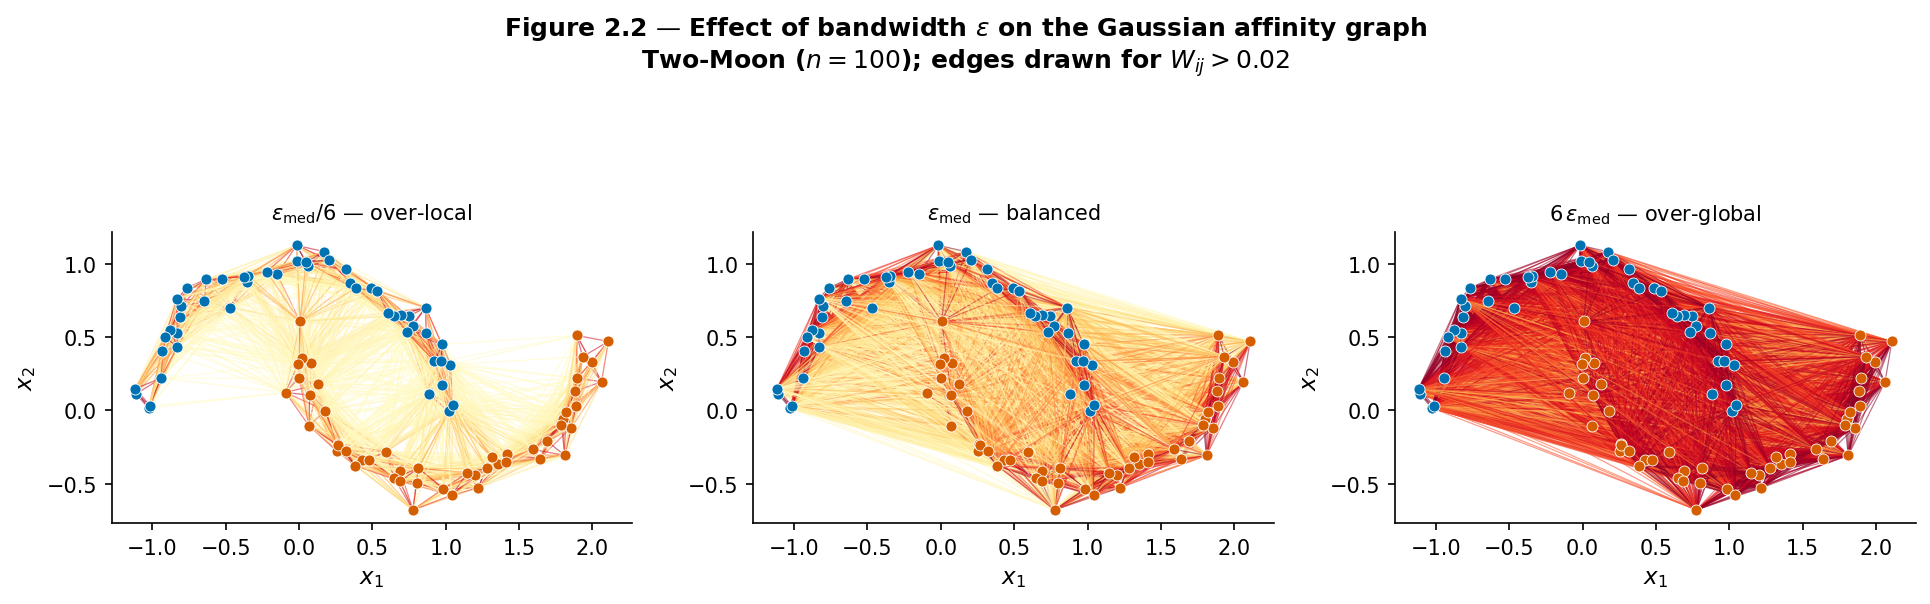

In [ ]:

# ── Figure 2.2 — Bandwidth ε sensitivity on the affinity graph ──────────────
np.random.seed(1)
n_sm = 100
X_sm, y_sm = make_moons(n_samples=n_sm, noise=0.07, random_state=1)

D2_sm    = cdist(X_sm, X_sm, 'sqeuclidean')
eps_med  = float(np.median(D2_sm[D2_sm > 0]))
eps_list = [eps_med / 6, eps_med, eps_med * 6]
ep_lbls  = [
    r'$\varepsilon_{\rm med}/6$ — over-local',
    r'$\varepsilon_{\rm med}$ — balanced',
    r'$6\,\varepsilon_{\rm med}$ — over-global',
]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
fig.suptitle(
    r'Figure 2.2 — Effect of bandwidth $\varepsilon$ on the Gaussian affinity graph'
    '\n' r'Two-Moon ($n = 100$); edges drawn for $W_{ij} > 0.02$',
    fontsize=12, fontweight='bold')

cmap_e = plt.get_cmap('YlOrRd')
cls_col = [CB['blue'], CB['vermilion']]

for ax, eps_v, lbl in zip(axes, eps_list, ep_lbls):
    W_ = np.exp(-D2_sm / eps_v)
    W_ -= np.diag(np.diag(W_))          # zero diagonal for clarity
    # Draw edges above threshold
    for i in range(n_sm):
        for j in range(i + 1, n_sm):
            w = W_[i, j]
            if w > 0.02:
                ax.plot([X_sm[i, 0], X_sm[j, 0]],
                        [X_sm[i, 1], X_sm[j, 1]],
                        color=cmap_e(w), lw=0.6, alpha=0.55, zorder=1)
    for c in [0, 1]:
        mask = y_sm == c
        ax.scatter(X_sm[mask, 0], X_sm[mask, 1],
                   c=cls_col[c], s=28, zorder=3,
                   edgecolors='white', linewidths=0.4)
    ax.set_title(lbl, fontsize=10, pad=6)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_aspect('equal')

plt.tight_layout(rect=[0, 0, 1, 0.84])
fig.savefig('pictures/fig2_2_epsilon_sensitivity.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 2.2 saved  (fig2_2_epsilon_sensitivity.pdf, 300 DPI)")


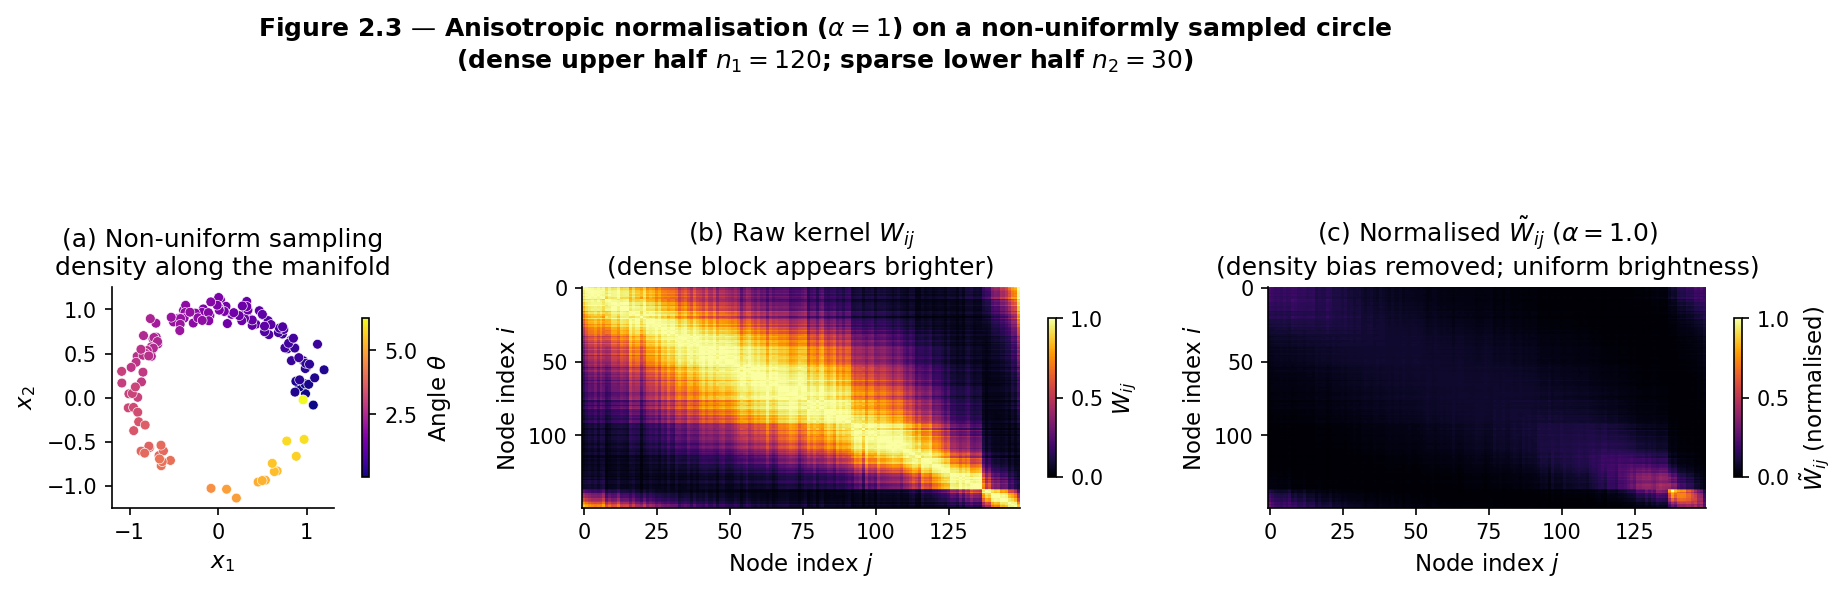

Saved: fig2_3_anisotropic_normalisation.pdf


In [16]:
# ── Figure 2.3 — Anisotropic normalisation on a non-uniform circle ──────────
np.random.seed(2)
# Non-uniform sampling: dense upper semicircle, sparse lower semicircle
theta_d = np.random.uniform(0, np.pi,      120)   # dense top
theta_s = np.random.uniform(np.pi, 2*np.pi, 30)   # sparse bottom
theta_all = np.concatenate([theta_d, theta_s])
idx_s = np.argsort(theta_all)
theta_all = theta_all[idx_s]                        # sorted by angle

X_nu = (np.column_stack([np.cos(theta_all), np.sin(theta_all)])
        + np.random.randn(150, 2) * 0.07)

D2_nu  = cdist(X_nu, X_nu, 'sqeuclidean')
eps_nu = float(np.median(D2_nu[D2_nu > 0]))
W_raw  = np.exp(-D2_nu / eps_nu)

# α = 1 normalisation
q       = W_raw.sum(axis=1)
alpha_d = 1.0
W_tilde = W_raw / np.outer(q**alpha_d, q**alpha_d)
W_tn    = W_tilde / W_tilde.max()   # rescale to [0,1] for display

fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
fig.suptitle(
    r'Figure 2.3 — Anisotropic normalisation ($\alpha = 1$) on a non-uniformly sampled circle'
    '\n(dense upper half $n_1 = 120$; sparse lower half $n_2 = 30$)',
    fontsize=12, fontweight='bold')

# (a) Scatter showing density variation
sc0 = axes[0].scatter(X_nu[:, 0], X_nu[:, 1],
                      c=theta_all, cmap='plasma', s=22,
                      edgecolors='white', linewidths=0.3)
axes[0].set_title('(a) Non-uniform sampling\ndensity along the manifold', pad=6)
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].set_aspect('equal')
plt.colorbar(sc0, ax=axes[0], shrink=0.72, label='Angle $\\theta$')

# (b) Raw W heatmap (sorted by angle — nodes ordered 0→2π)
im1 = axes[1].imshow(W_raw, cmap='inferno', aspect='auto',
                     interpolation='nearest', vmin=0, vmax=1)
axes[1].set_title('(b) Raw kernel $W_{ij}$\n(dense block appears brighter)', pad=6)
axes[1].set_xlabel('Node index $j$')
axes[1].set_ylabel('Node index $i$')
plt.colorbar(im1, ax=axes[1], shrink=0.72, label='$W_{ij}$')

# (c) Normalised W̃ heatmap
im2 = axes[2].imshow(W_tn, cmap='inferno', aspect='auto',
                     interpolation='nearest', vmin=0, vmax=1)
axes[2].set_title(f'(c) Normalised $\\tilde{{W}}_{{ij}}$ ($\\alpha = {alpha_d}$)\n'
                  '(dense-region brightness bias is substantially reduced)', pad=6)
axes[2].set_xlabel('Node index $j$')
axes[2].set_ylabel('Node index $i$')
plt.colorbar(im2, ax=axes[2], shrink=0.72, label='$\\tilde{W}_{ij}$ (normalised)')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_3_anisotropic_normalisation.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_3_anisotropic_normalisation.pdf")

---
## §2.3 Markov Operator and Random Walk Dynamics

From the normalised kernel $\widetilde{W}$, define the **row sums**

$$
\tilde{d}_i = \sum_{j=1}^{n} \widetilde{W}_{ij},
$$

and the **row-stochastic transition matrix**

$$
P_{ij} = \frac{\widetilde{W}_{ij}}{\tilde{d}_i}.
$$

Each row of $P$ is a probability distribution: $P_{ij}$ is the probability that a random walk at node $i$ transitions to node $j$ in one step.  The **$t$-step transition matrix** $P^t$ has entries $P^t_{ij}$ representing the probability of reaching $j$ from $i$ in exactly $t$ steps, integrating all possible $t$-hop paths.

From a geometric viewpoint:
- **$t = 1$** captures *immediate* local neighbourhood (single-hop structure).
- **Larger $t$** aggregates multi-hop paths, progressively incorporating larger-scale manifold connectivity.
- As $t \to \infty$, rows of $P^t$ converge to the **stationary distribution** $\pi$, losing all structural information.

The diffusion time $t$ therefore provides a principled, continuously adjustable scale parameter: small $t$ preserves fine local structure, large $t$ emphasises global topology at the cost of local detail.  **Figure 2.4** demonstrates this spreading behaviour with the transition-probability row $P^t_{i,\cdot}$ for a fixed starting node.

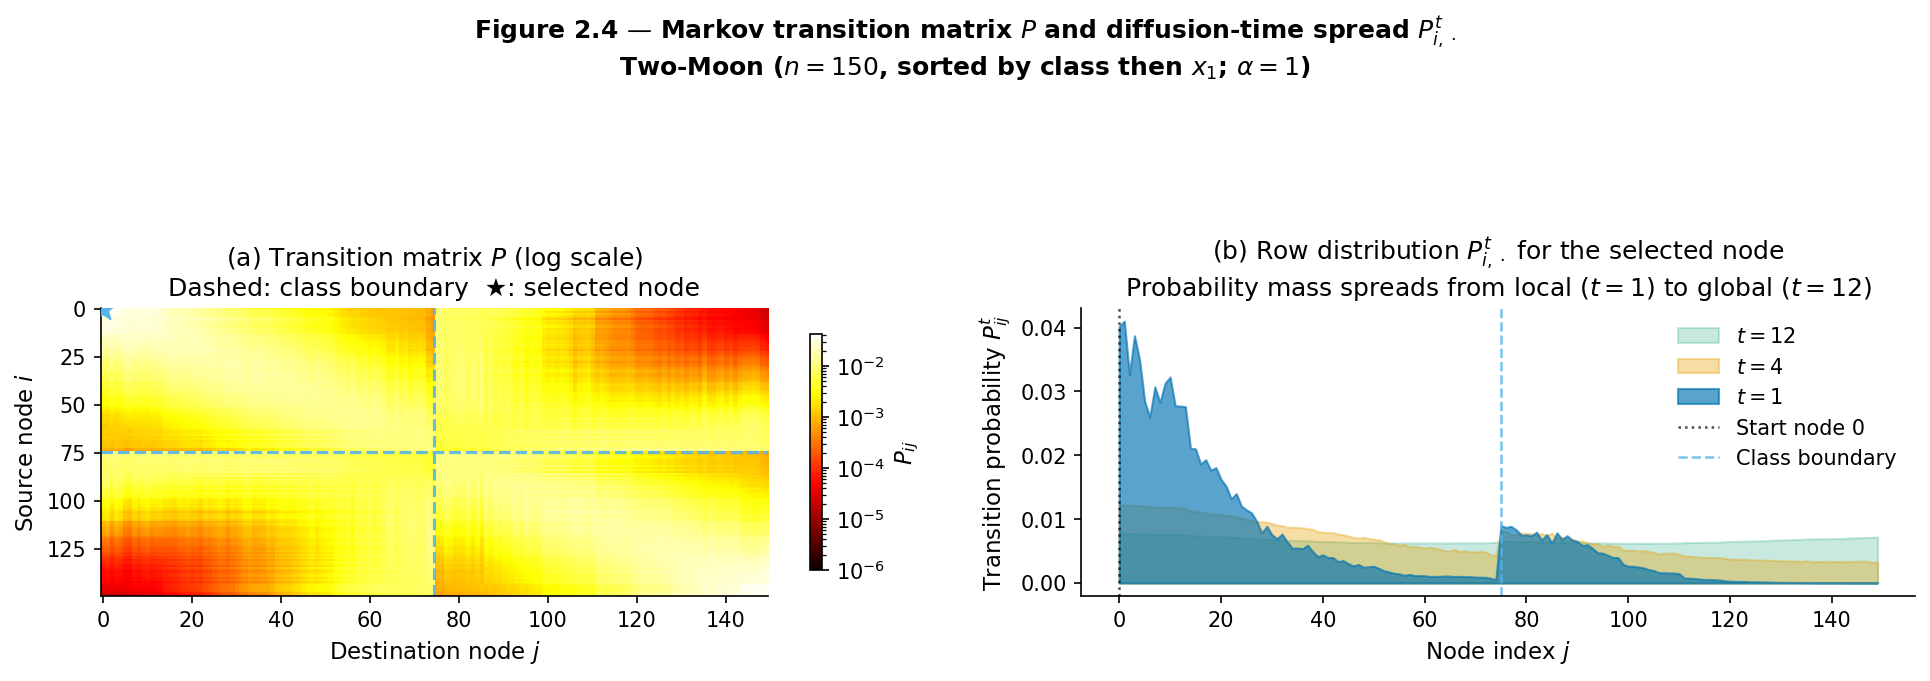

Saved: fig2_4_markov_dynamics.pdf


In [17]:
# ── Figure 2.4 — Markov transition matrix and diffusion spread ───────────────
np.random.seed(4)
n_mk = 150
X_mk, y_mk = make_moons(n_samples=n_mk, noise=0.07, random_state=4)
# Sort by class then x1 for clean block structure in heatmap
idx_mk  = np.argsort(y_mk * 100 + X_mk[:, 0])
X_mk    = X_mk[idx_mk]
y_mk    = y_mk[idx_mk]
n_cls0  = int((y_mk == 0).sum())

_, _, P_mk, _, _, _ = build_diffusion_map(X_mk, epsilon='median', alpha=1.0,
                                          n_components=8)

# Pick a starting node near the tip of class-0 moon
node_idx = np.argmin(X_mk[y_mk == 0, 0])   # leftmost point in class 0
node_idx = np.where(y_mk == 0)[0][node_idx]

# Compute P^t rows via repeated matrix multiplication (n=150 → fast)
Pt1  = P_mk[node_idx].copy()
Pt4  = np.linalg.matrix_power(P_mk, 4)[node_idx]
Pt12 = np.linalg.matrix_power(P_mk, 12)[node_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fig.suptitle(
    r'Figure 2.4 — Markov transition matrix $P$ and diffusion-time spread $P^t_{i,\cdot}$'
    '\n' r'Two-Moon ($n = 150$, sorted by class then $x_1$; $\alpha = 1$)',
    fontsize=12, fontweight='bold')

# (a) P heatmap (log scale to reveal off-diagonal structure)
P_disp = np.clip(P_mk, 1e-8, None)
im = axes[0].imshow(P_disp, cmap='hot', aspect='auto', interpolation='nearest',
                    norm=mpl.colors.LogNorm(vmin=1e-6, vmax=P_mk.max()))
axes[0].axhline(n_cls0 - 0.5, color=CB['sky'], lw=1.5, ls='--', alpha=0.9)
axes[0].axvline(n_cls0 - 0.5, color=CB['sky'], lw=1.5, ls='--', alpha=0.9)
axes[0].scatter([node_idx], [node_idx], marker='*', s=130, c=CB['sky'], zorder=5)
axes[0].set_title('(a) Transition matrix $P$ (log scale)\n'
                  'Dashed: class boundary  ★: selected node', pad=6)
axes[0].set_xlabel('Destination node $j$')
axes[0].set_ylabel('Source node $i$')
plt.colorbar(im, ax=axes[0], shrink=0.82, label='$P_{ij}$')

# (b) Diffusion-spread row distributions
xn = np.arange(n_mk)
axes[1].fill_between(xn, Pt12, alpha=0.22, color=CB['green'],     label='$t = 12$')
axes[1].fill_between(xn, Pt4,  alpha=0.35, color=CB['orange'],    label='$t = 4$')
axes[1].fill_between(xn, Pt1,  alpha=0.65, color=CB['blue'],      label='$t = 1$')
axes[1].axvline(node_idx,  color='black',   ls=':',  lw=1.2, alpha=0.7,
                label=f'Start node {node_idx}')
axes[1].axvline(n_cls0,    color=CB['sky'], ls='--', lw=1.2, alpha=0.8,
                label='Class boundary')
axes[1].set_title('(b) Row distribution $P^t_{i,\\cdot}$ for the selected node\n'
                  'Probability mass spreads from local $(t=1)$ to global $(t=12)$',
                  pad=6)
axes[1].set_xlabel('Node index $j$')
axes[1].set_ylabel('Transition probability $P^t_{ij}$')
axes[1].legend(frameon=False, loc='upper right')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_4_markov_dynamics.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_4_markov_dynamics.pdf")

---
## §2.4 Spectral Decomposition and Diffusion Coordinates

Let $(\lambda_\ell, \psi_\ell)$ be the right eigenpairs of $P$:

$$
P\,\psi_\ell = \lambda_\ell\,\psi_\ell, \qquad 1 = \lambda_0 \geq \lambda_1 \geq \lambda_2 \geq \cdots \geq 0.
$$

Because $P$ is a similarity transformation of the symmetric matrix $A = D^{-1/2}\widetilde{W}D^{-1/2}$, it has real eigenvalues in $[0,1]$.  The trivial mode $\lambda_0 = 1$ corresponds to the stationary distribution and carries no discriminative information.  All structural information resides in the **non-trivial eigenvectors** $\psi_1, \psi_2, \dots$

The **diffusion coordinates** at diffusion time $t$ are:

$$
\Psi_t(x_i) = \bigl(\lambda_1^t\,\psi_1(i),\;\lambda_2^t\,\psi_2(i),\;\dots,\;\lambda_m^t\,\psi_m(i)\bigr) \in \mathbb{R}^m.
$$

The powers $\lambda_\ell^t$ act as a **spectral filter**:
- Eigenvalues close to 1 (slow-decaying modes) encode large-scale manifold structure.
- Eigenvalues near 0 decay rapidly with $t$, suppressing high-frequency noise components.
- A **spectral gap** after the first $m$ eigenvalues signals an intrinsic dimensionality of $m$.

A practical benefit is that changing $t$ only requires rescaling the existing eigenvectors — no recomputation of the eigendecomposition.  **Figure 2.5** shows the eigenvalue spectrum and the resulting two-dimensional diffusion embedding on the Swiss Roll.

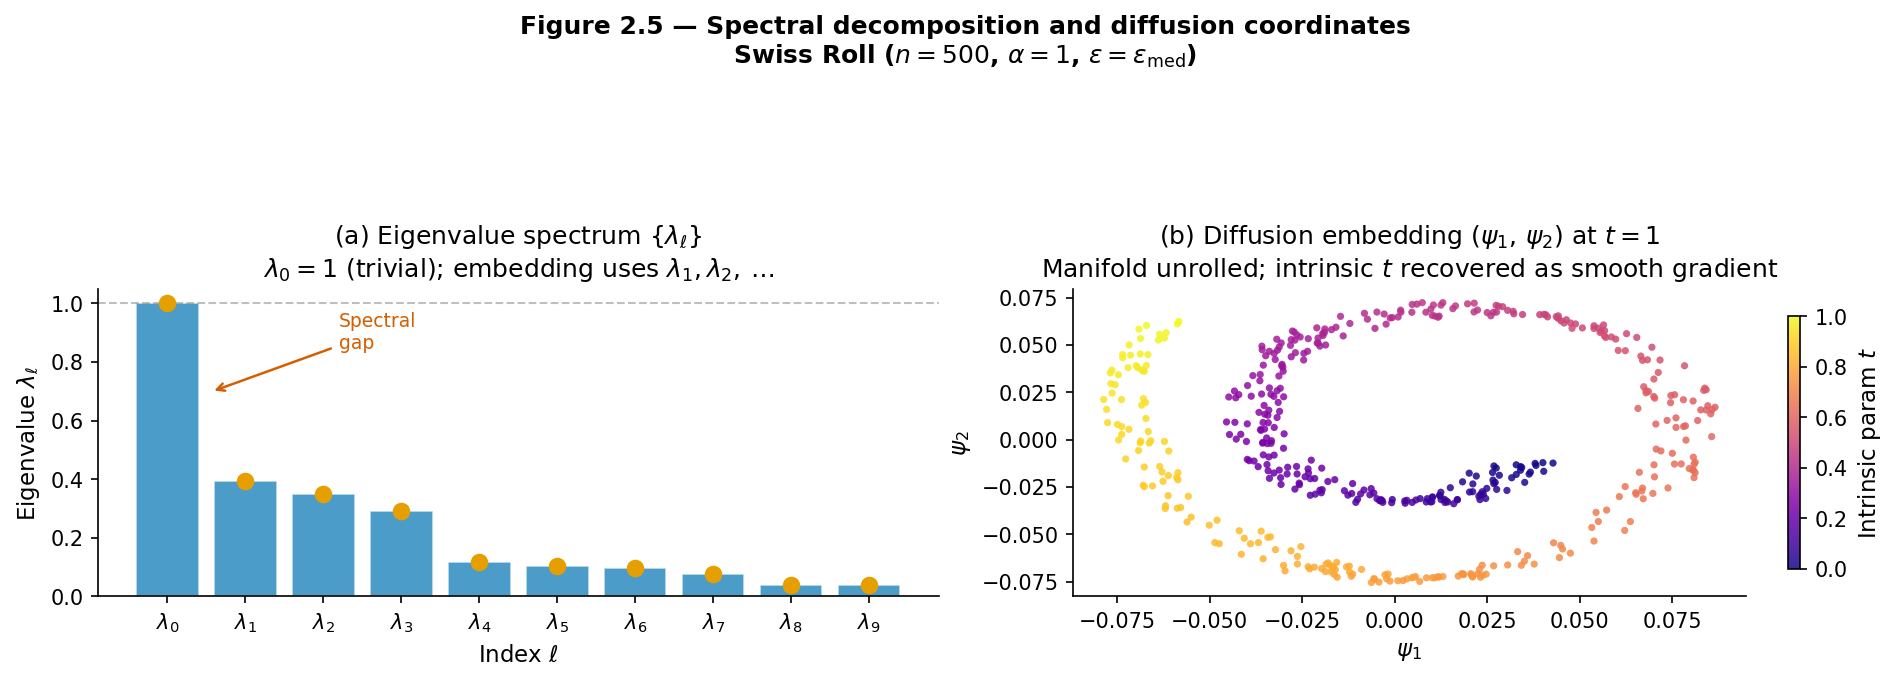

Saved: fig2_5_spectral_embedding.pdf


In [18]:
# ── Figure 2.5 — Eigenvalue spectrum and 2-D diffusion embedding ─────────────
np.random.seed(5)
n_emb  = 500
X_emb, t_emb = make_swiss_roll(n_samples=n_emb, noise=0.10, random_state=5)
t_emb_n = (t_emb - t_emb.min()) / (t_emb.max() - t_emb.min())

vals_e, psi_e, _, _, _, _ = build_diffusion_map(
    X_emb, epsilon='median', alpha=1.0, n_components=10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fig.suptitle(
    r'Figure 2.5 — Spectral decomposition and diffusion coordinates'
    '\n' r'Swiss Roll ($n = 500$, $\alpha = 1$, $\varepsilon = \varepsilon_{\rm med}$)',
    fontsize=12, fontweight='bold')

# (a) Eigenvalue spectrum
k_show  = 10
indices = np.arange(k_show)
axes[0].bar(indices, vals_e[:k_show],
            color=CB['blue'], alpha=0.70, edgecolor='white', linewidth=0.8)
axes[0].scatter(indices, vals_e[:k_show],
                color=CB['orange'], s=55, zorder=5)
axes[0].axhline(1.0, color='grey', ls='--', lw=1.0, alpha=0.5)

# Annotate spectral gap (largest drop after trivial mode)
gaps  = -np.diff(vals_e[:k_show])
g_idx = int(np.argmax(gaps))
y_mid = float((vals_e[g_idx] + vals_e[g_idx + 1]) / 2)
axes[0].annotate(
    'Spectral\ngap',
    xy=(g_idx + 0.55, y_mid),
    xytext=(g_idx + 2.2, y_mid + 0.15),
    fontsize=9, color=CB['vermilion'],
    arrowprops=dict(arrowstyle='->', color=CB['vermilion'], lw=1.2))
axes[0].set_title(r'(a) Eigenvalue spectrum $\{\lambda_\ell\}$'
                  '\n' r'$\lambda_0 = 1$ (trivial); embedding uses $\lambda_1, \lambda_2, \dots$',
                  pad=6)
axes[0].set_xlabel(r'Index $\ell$')
axes[0].set_ylabel(r'Eigenvalue $\lambda_\ell$')
axes[0].set_xticks(indices)
axes[0].set_xticklabels([f'$\\lambda_{{{i}}}$' for i in indices])

# (b) 2-D diffusion embedding (ψ₁ vs ψ₂, coloured by intrinsic t)
sc = axes[1].scatter(psi_e[:, 1], psi_e[:, 2],
                     c=t_emb_n, cmap='plasma', s=12, alpha=0.85, linewidths=0)
axes[1].set_title(r'(b) Diffusion embedding $(\psi_1,\,\psi_2)$ at $t = 1$'
                  '\nManifold unrolled; intrinsic $t$ recovered as smooth gradient',
                  pad=6)
axes[1].set_xlabel(r'$\psi_1$')
axes[1].set_ylabel(r'$\psi_2$')
fig.colorbar(sc, ax=axes[1], shrink=0.82, label='Intrinsic param $t$')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_5_spectral_embedding.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_5_spectral_embedding.pdf")

---
## §2.5 Diffusion Distance and Its Interpretation

The **diffusion distance** at time $t$ between nodes $i$ and $j$ is defined as

$$
D_t^2(i, j) = \sum_{k=1}^{n} \frac{\bigl(P^t_{ik} - P^t_{jk}\bigr)^2}{\pi_k},
$$

where $\pi$ is the stationary distribution of the random walk.  Two points are *close in diffusion distance* when their $t$-step transition **distributions over all nodes** are similar — that is, they reach the same regions of the manifold with similar probability.

This criterion is often stronger than Euclidean proximity:

| Scenario | Euclidean distance | Diffusion distance | Manifold relationship |
|---|---|---|---|
| Two points on opposite arms of Two-Moon, near the boundary | **small** | **large** | Different manifold regions |
| Two points on the same moon arm, far apart | **large** | **small** | Same manifold region, connected via diffusion paths |

Using the spectral expansion, the diffusion distance is efficiently approximated by

$$
D_t^2(i, j) \approx \sum_{\ell=1}^{m} \lambda_\ell^{2t}\,\bigl(\psi_\ell(i) - \psi_\ell(j)\bigr)^2,
$$

which corresponds to **squared Euclidean distance** in the scaled diffusion coordinate space $\{\lambda_\ell^t \psi_\ell\}$.  This supports using standard Euclidean algorithms (clustering, regression) directly in the diffusion embedding, with approximation mainly controlled by the truncation level $m$.  **Figure 2.6** illustrates how diffusion distance separates the two classes of Two-Moon more cleanly than Euclidean distance.

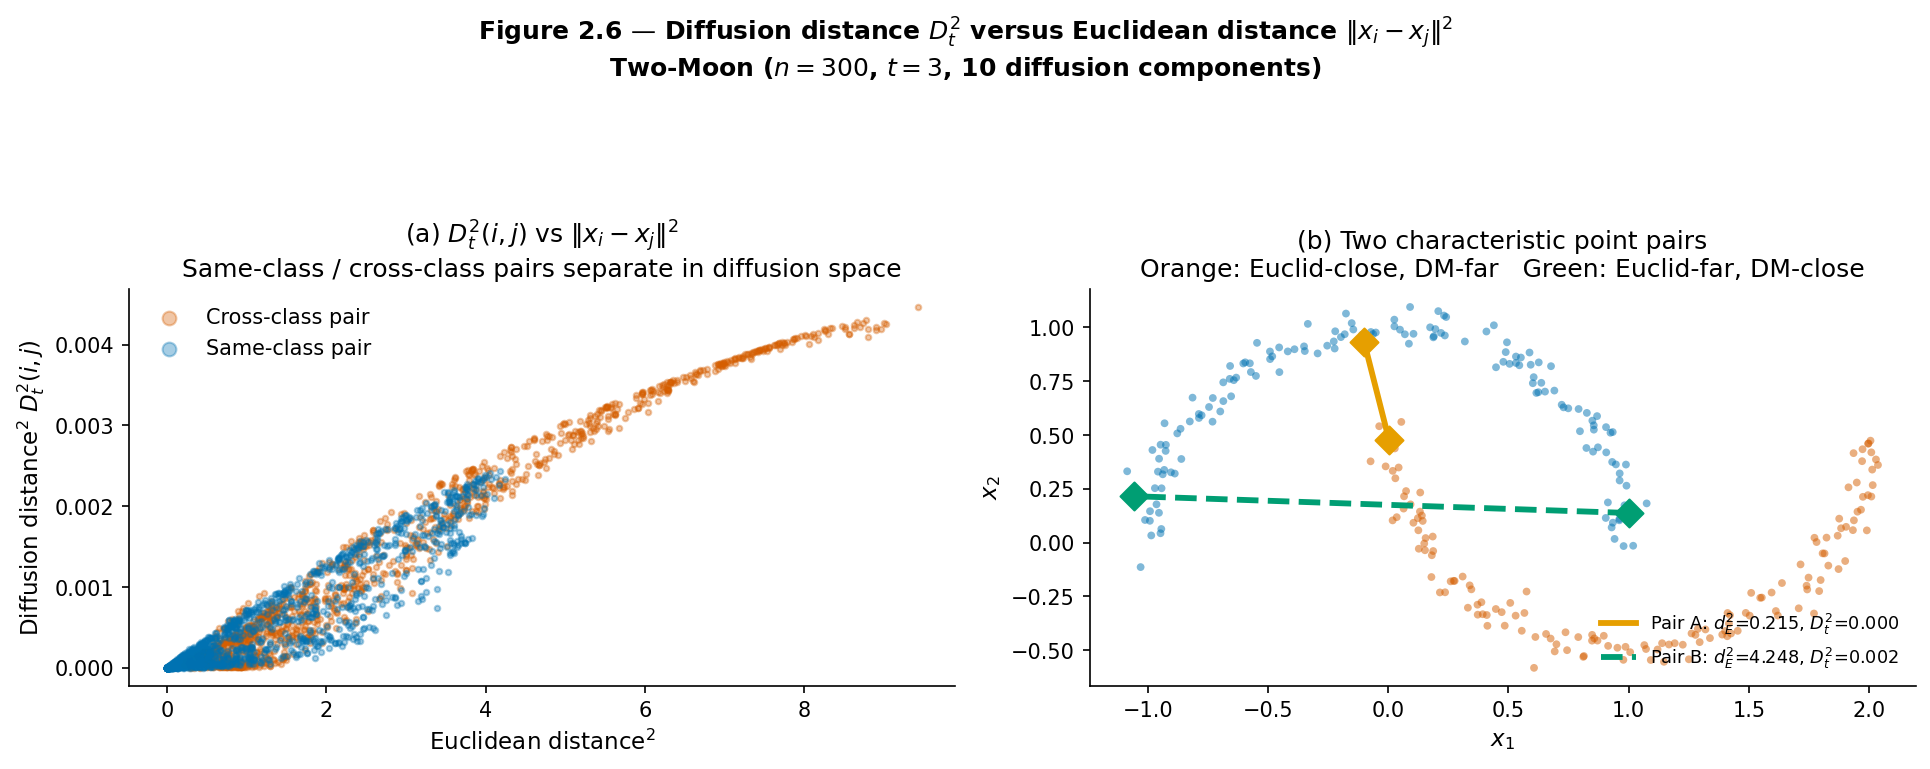

Saved: fig2_6_diffusion_distance.pdf


In [19]:
# ── Figure 2.6 — Diffusion distance vs Euclidean distance ───────────────────
np.random.seed(6)
n_dd = 300
X_dd, y_dd = make_moons(n_samples=n_dd, noise=0.05, random_state=6)

vals_dd, psi_dd, _, _, _, _ = build_diffusion_map(
    X_dd, epsilon='median', alpha=1.0, n_components=15)

# Spectral diffusion distance²: D_t²(i,j) = Σ_{l≥1} λ_l^{2t} (ψ_l(i)-ψ_l(j))²
t_diff    = 3
n_use     = 10   # non-trivial components
lam_2t    = vals_dd[1:n_use + 1] ** (2 * t_diff)
psi_sc    = psi_dd[:, 1:n_use + 1] * np.sqrt(lam_2t)[None, :]
D_diff    = cdist(psi_sc, psi_sc, 'sqeuclidean')
D_euc     = cdist(X_dd,  X_dd,  'sqeuclidean')

# Sample random pairs (i != j)
rng    = np.random.default_rng(42)
i_idx  = rng.integers(0, n_dd, 3000)
j_idx  = rng.integers(0, n_dd, 3000)
valid  = i_idx != j_idx
i_idx, j_idx = i_idx[valid][:2500], j_idx[valid][:2500]
same   = y_dd[i_idx] == y_dd[j_idx]

euc_v  = D_euc[i_idx, j_idx]
dif_v  = D_diff[i_idx, j_idx]

# Find extreme pairs for annotation
cross_idx = np.where(~same)[0]
same_idx  = np.where(same)[0]
pA = cross_idx[np.argmin(euc_v[cross_idx])]
iA, jA = int(i_idx[pA]), int(j_idx[pA])
pB = same_idx[np.argmax(euc_v[same_idx])]
iB, jB = int(i_idx[pB]), int(j_idx[pB])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
fig.suptitle(
    r'Figure 2.6 — Diffusion distance $D_t^2$ versus Euclidean distance $\|x_i - x_j\|^2$'
    f'\nTwo-Moon ($n = {n_dd}$, $t = {t_diff}$, {n_use} diffusion components)',
    fontsize=12, fontweight='bold')

# (a) Scatter coloured by class relationship
axes[0].scatter(euc_v[~same], dif_v[~same],
                c=CB['vermilion'], s=7, alpha=0.35, label='Cross-class pair')
axes[0].scatter(euc_v[same], dif_v[same],
                c=CB['blue'],     s=7, alpha=0.35, label='Same-class pair')
axes[0].set_title(r'(a) $D_t^2(i,j)$ vs $\|x_i - x_j\|^2$'
                  '\nSame-class / cross-class pairs separate in diffusion space',
                  pad=6)
axes[0].set_xlabel(r'Euclidean distance$^2$')
axes[0].set_ylabel(r'Diffusion distance$^2$ $D_t^2(i,j)$')
axes[0].legend(frameon=False, markerscale=2.5)

# (b) Data with the two highlighted pairs
cls_col = [CB['blue'] if c == 0 else CB['vermilion'] for c in y_dd]
axes[1].scatter(X_dd[:, 0], X_dd[:, 1],
                c=cls_col, s=14, alpha=0.50, linewidths=0, zorder=2)
# Pair A (orange): Euclidean-close, diffusion-far
axes[1].plot([X_dd[iA, 0], X_dd[jA, 0]], [X_dd[iA, 1], X_dd[jA, 1]],
             color=CB['orange'], lw=2.8, zorder=4,
             label=f'Pair A: $d_E^2$={euc_v[pA]:.3f}, $D_t^2$={dif_v[pA]:.3f}')
axes[1].scatter([X_dd[iA, 0], X_dd[jA, 0]], [X_dd[iA, 1], X_dd[jA, 1]],
                color=CB['orange'], s=90, zorder=5, marker='D')
# Pair B (green): Euclidean-far, diffusion-close
axes[1].plot([X_dd[iB, 0], X_dd[jB, 0]], [X_dd[iB, 1], X_dd[jB, 1]],
             color=CB['green'], lw=2.8, zorder=4, ls='--',
             label=f'Pair B: $d_E^2$={euc_v[pB]:.3f}, $D_t^2$={dif_v[pB]:.3f}')
axes[1].scatter([X_dd[iB, 0], X_dd[jB, 0]], [X_dd[iB, 1], X_dd[jB, 1]],
                color=CB['green'], s=90, zorder=5, marker='D')
axes[1].set_title('(b) Two characteristic point pairs\n'
                  'Orange: Euclid-close, DM-far   Green: Euclid-far, DM-close',
                  pad=6)
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
axes[1].legend(frameon=False, fontsize=8.5, loc='lower right')

plt.tight_layout(rect=[0, 0, 1, 0.87])
fig.savefig('pictures/fig2_6_diffusion_distance.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_6_diffusion_distance.pdf")

---
## §2.6 Connection to Continuous Operators

Under regular sampling and appropriate scaling of $\varepsilon$ with $n$, normalised graph operators converge to **differential operators on the underlying manifold** $\mathcal{M}$.  Specifically, as $n \to \infty$ and $\varepsilon \to 0$ at appropriate rates, the normalised diffusion operator converges to the **Laplace–Beltrami operator** on $\mathcal{M}$:

$$
\frac{I - P}{\varepsilon} \;\xrightarrow{n \to \infty}\; \Delta_{\mathcal{M}},
$$

where $\Delta_{\mathcal{M}}$ is the intrinsic Laplacian on the manifold.  The eigenfunctions of $\Delta_{\mathcal{M}}$ are the continuous limits of the discrete eigenvectors $\psi_\ell$.

This continuum limit provides two key theoretical motivations:

1. **Intrinsic coordinate recovery tendency** — Under standard regularity assumptions, Diffusion Map eigenvectors approximate manifold coordinates rather than arbitrary graph artefacts.
2. **Noise robustness tendency** — Because the Laplacian smooths high-frequency perturbations, the embedding tends to remain stable under small additive noise in $\mathcal{X}$, provided $\varepsilon$ is chosen sensibly relative to the noise scale.

With $\alpha = 1$, the limit operator is the Laplace–Beltrami operator intrinsic to $\mathcal{M}$ — independent of the sampling density.  For $\alpha = 0$, the limit is instead the Fokker–Planck operator, which depends on the density and is appropriate for different applications.

---
## §2.7 Role of Hyperparameters in Theory

Theoretical behaviour is governed by four coupled design choices:

| Parameter | Symbol | Effect |
|---|---|---|
| Kernel bandwidth | $\varepsilon$ | Sets neighbourhood radius; controls local–global trade-off in graph connectivity |
| Density correction | $\alpha$ | $\alpha=0$: raw graph; $\alpha=1$: geometry-preserving, density-independent Laplacian |
| Diffusion time | $t$ | Smaller $t$: fine local detail; larger $t$: smooth global structure; governs noise suppression |
| Embedding dimension | $m$ | Truncates spectral representation; should be chosen at or just before a spectral gap |

A practical selection principle: choose $\varepsilon$ so that the graph is **connected** and each point has a moderate effective number of neighbours; choose $m$ at the **spectral gap**; and adjust $t$ to balance local fidelity against noise suppression.

**Figure 2.7** provides a representative comparison: PCA on Swiss Roll versus Diffusion Map, both coloured by the intrinsic parameter $t$.  PCA projects onto linear variance directions and entangles the roll, while Diffusion Map unrolls the manifold more clearly and recovers intrinsic structure as a smooth gradient in $(\psi_1, \psi_2)$ space.

> **Chapter summary** — This chapter formalised the four-step Diffusion Map pipeline (affinity graph → anisotropic normalisation → Markov operator → spectral embedding), established the connection to the Laplace–Beltrami operator, and demonstrated each theoretical component through figures on synthetic manifold data.  Chapter 3 translates these theoretical choices into a reproducible implementation and hyperparameter strategy.

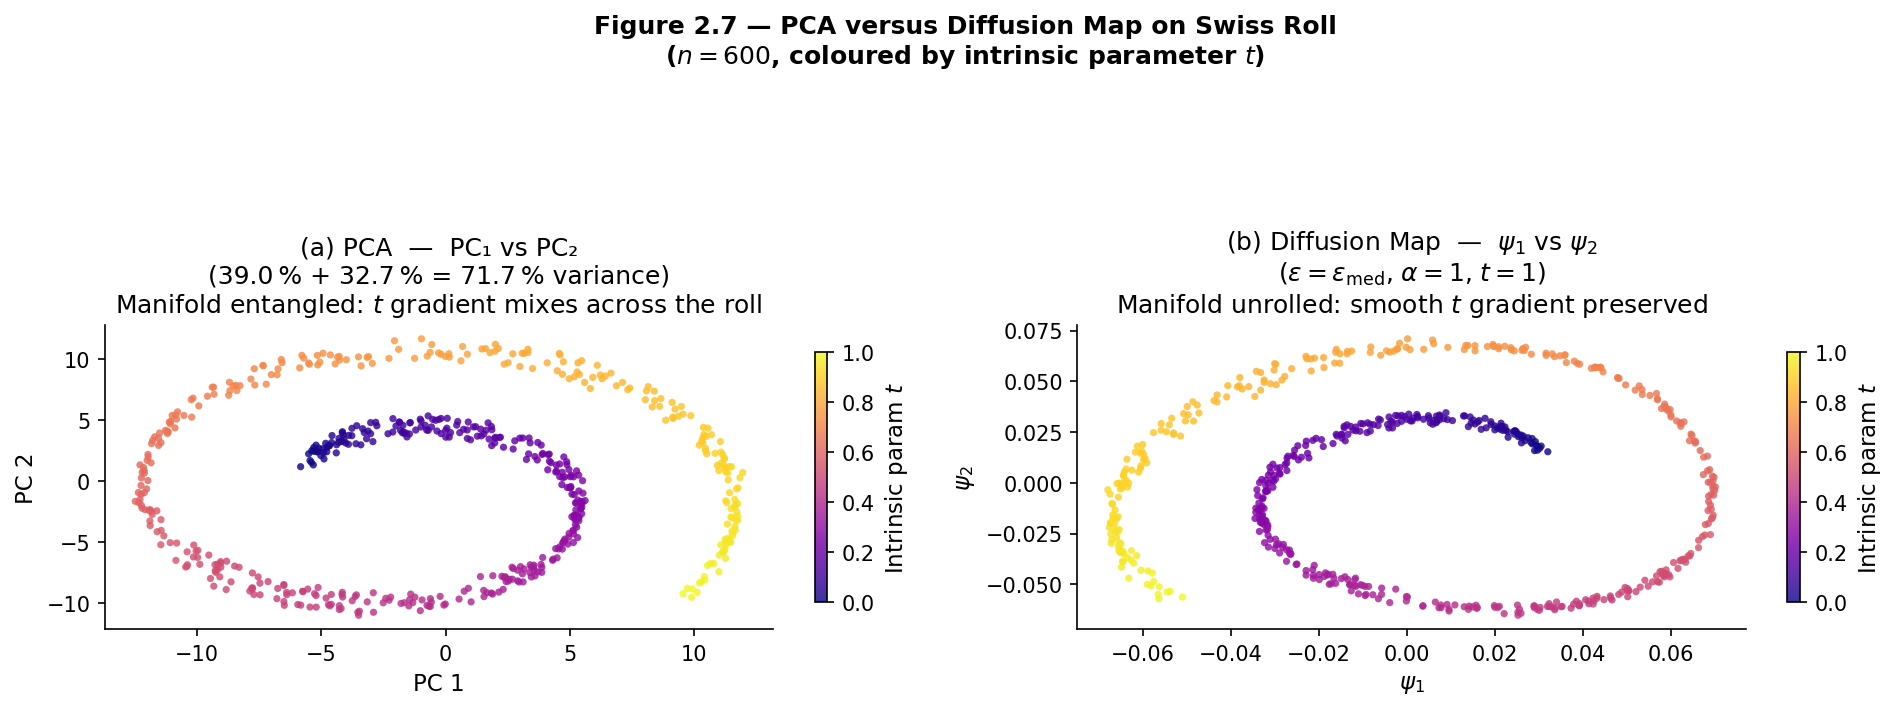

Saved: fig2_7_pca_vs_diffusion.pdf


In [20]:
# ── Figure 2.7 — PCA vs Diffusion Map on Swiss Roll ─────────────────────────
np.random.seed(7)
n_cmp = 600
X_cmp, t_cmp = make_swiss_roll(n_samples=n_cmp, noise=0.12, random_state=7)
t_cmp_n = (t_cmp - t_cmp.min()) / (t_cmp.max() - t_cmp.min())

# PCA reduction to 2D
pca      = PCA(n_components=2)
X_pca    = pca.fit_transform(X_cmp)
pca_var  = pca.explained_variance_ratio_

# Diffusion Map reduction to 2D
vals_c, psi_c, _, _, _, _ = build_diffusion_map(
    X_cmp, epsilon='median', alpha=1.0, n_components=6)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
fig.suptitle(
    'Figure 2.7 — PCA versus Diffusion Map on Swiss Roll\n'
    r'($n = 600$, coloured by intrinsic parameter $t$)',
    fontsize=12, fontweight='bold')

# (a) PCA
sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1],
                      c=t_cmp_n, cmap='plasma', s=12, alpha=0.82, linewidths=0)
axes[0].set_title(
    '(a) PCA  —  PC₁ vs PC₂\n'
    f'({100*pca_var[0]:.1f}\u202f% + {100*pca_var[1]:.1f}\u202f%'
    f' = {100*sum(pca_var[:2]):.1f}\u202f% variance)\n'
    'Manifold remains entangled: $t$ gradient mixes across the roll',
    pad=6)
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
fig.colorbar(sc1, ax=axes[0], shrink=0.82, label='Intrinsic param $t$')

# (b) Diffusion Map
sc2 = axes[1].scatter(psi_c[:, 1], psi_c[:, 2],
                      c=t_cmp_n, cmap='plasma', s=12, alpha=0.82, linewidths=0)
axes[1].set_title(
    r'(b) Diffusion Map  —  $\psi_1$ vs $\psi_2$'
    '\n' r'($\varepsilon = \varepsilon_{\rm med}$, $\alpha = 1$, $t = 1$)'
    '\nManifold is more clearly unrolled: smoother $t$ gradient is preserved',
    pad=6)
axes[1].set_xlabel(r'$\psi_1$')
axes[1].set_ylabel(r'$\psi_2$')
fig.colorbar(sc2, ax=axes[1], shrink=0.82, label='Intrinsic param $t$')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_7_pca_vs_diffusion.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_7_pca_vs_diffusion.pdf")